# Lista 7

Zuzanna Sosnowska

In [1]:
import numpy as np
import pandas as pd
from typing import Literal, Callable
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

### Zadanie 1

**Instalacja i wstęp:** Zainstaluj `PyTorch` lub `TensorFlow`. Wytwórz proste tensory (lub tablice) i wykonaj na nich podstawowe operacje (dodawanie, mnożenie, transpozycja).

In [2]:
import torch

list_of_lists = [[1, 2, 3, 4, 5],[6, 7, 8, 9, 10]]
np_array = np.arange(0, 1, 0.1)
shape = (2,5)

tensor_1 = torch.tensor(list_of_lists)
tensor_2 = torch.from_numpy(np_array)
tensor_3 = torch.rand(shape)

print(tensor_1, tensor_2, tensor_3, sep='\n')

tensor([[ 1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10]])
tensor([0.0000, 0.1000, 0.2000, 0.3000, 0.4000, 0.5000, 0.6000, 0.7000, 0.8000,
        0.9000], dtype=torch.float64)
tensor([[0.2690, 0.5724, 0.3965, 0.6596, 0.6050],
        [0.9907, 0.9742, 0.0342, 0.4307, 0.4059]])


In [3]:
print(tensor_1 + tensor_3)

print(torch.add(tensor_1, tensor_3))

tensor([[ 1.2690,  2.5724,  3.3965,  4.6596,  5.6050],
        [ 6.9907,  7.9742,  8.0342,  9.4307, 10.4059]])
tensor([[ 1.2690,  2.5724,  3.3965,  4.6596,  5.6050],
        [ 6.9907,  7.9742,  8.0342,  9.4307, 10.4059]])


In [4]:
print(2 * tensor_1)
print(torch.mul(tensor_1, tensor_1))
print(tensor_1 * tensor_1)

tensor([[ 2,  4,  6,  8, 10],
        [12, 14, 16, 18, 20]])
tensor([[  1,   4,   9,  16,  25],
        [ 36,  49,  64,  81, 100]])
tensor([[  1,   4,   9,  16,  25],
        [ 36,  49,  64,  81, 100]])


In [5]:
print(tensor_1.T)

tensor([[ 1,  6],
        [ 2,  7],
        [ 3,  8],
        [ 4,  9],
        [ 5, 10]])


In [6]:
print(tensor_1 @ tensor_1.T)
print(tensor_1.matmul(tensor_1.T))

tensor([[ 55, 130],
        [130, 330]])
tensor([[ 55, 130],
        [130, 330]])


In [7]:
import tensorflow as tf

t1 = tf.convert_to_tensor(list_of_lists)
print(t1)
print(t1 + t1)
print(3 * t1)
print(t1 * t1)
print(t1 @ tf.transpose(t1))

tf.Tensor(
[[ 1  2  3  4  5]
 [ 6  7  8  9 10]], shape=(2, 5), dtype=int32)
tf.Tensor(
[[ 2  4  6  8 10]
 [12 14 16 18 20]], shape=(2, 5), dtype=int32)
tf.Tensor(
[[ 3  6  9 12 15]
 [18 21 24 27 30]], shape=(2, 5), dtype=int32)
tf.Tensor(
[[  1   4   9  16  25]
 [ 36  49  64  81 100]], shape=(2, 5), dtype=int32)
tf.Tensor(
[[ 55 130]
 [130 330]], shape=(2, 2), dtype=int32)


### Zadanie 2

**Budowa prostej sieci neuronowej:** Stwórz model sztucznej sieci neuronowej (ANN) z jedną warstwą wejściową, jedną ukrytą i jedną wyjściową. Użyj danych syntetycznych, aby model nauczył się prostej zależności regresyjnej (np. $y = 2x + 1$).

In [8]:
def identity(x): return x
def identity_derivative(x): return np.ones_like(x)

def logistic(x): return 1 / (1 + np.exp(-x))
def logistic_derivative(x): return logistic(x) * (1 - logistic(x))

def tanh(x): return (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x))
def tanh_derivative(x): return 1 - np.power(tanh(x), 2)

def relu(x): return np.maximum(0, x)
def relu_derivative(x): return (x > 0).astype(float)

class MyArtificialNeutralNetwork:
    w1: np.ndarray
    w2: np.ndarray
    b1: float
    b2: float
    activation: Callable
    activation_derivative: Callable

    def __init__(self):
        pass

    def fit(self, X, y, activ_func: Literal['identity', 'logistic', 'tanh', 'relu']='relu', units: int = 8, epochs=50, lr=0.001):

        n_features, n_samples = X.shape

        w1 = np.random.normal(scale=0.1, size=(units, n_features))
        w2 = np.random.normal(scale=0.1, size=(1, units))
        b1 = np.zeros((units, 1))
        b2 = np.zeros((1, 1))

        match activ_func:
            case "identity":
                activation = identity
                activation_derivative = identity_derivative
            case "logistic":
                activation = logistic
                activation_derivative = logistic_derivative
            case "tanh":
                activation = tanh
                activation_derivative = tanh_derivative
            case "relu":
                activation = relu
                activation_derivative = relu_derivative
            case _:
                raise ValueError("Unknown activation function")

        for epoch in range(epochs):
            z1 = w1 @ X + b1
            a1 = activation(z1)
            z2 = w2 @ a1 + b2

            y_pred = z2

            dL_dy = 2 * (y_pred - y) / n_samples

            dw2 = dL_dy @ a1.T
            db2 = np.sum(dL_dy, axis=1, keepdims=True)

            da1 = w2.T @ dL_dy
            dz1 = da1 * activation_derivative(z1)

            dW1 = dz1 @ X.T
            db1 = np.sum(dz1, axis=1, keepdims=True)

            w1 -= lr * dW1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

        self.w1 = w1
        self.w2 = w2
        self.b1 = b1
        self.b2 = b2
        self.activation = activation
        self.activation_derivative = activation_derivative

    def predict(self, X):
        X = X.T
        z1 = self.w1 @ X + self.b1
        a1 = self.activation(z1)
        z2 = self.w2 @ a1 + self.b2
        return z2.flatten()

In [17]:
X = np.random.uniform(-10, 10, size=(1000, 1))
line = 2 * X + 1
y = line + np.random.normal(0, 1, size=(1000, 1))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

y_scaler = MinMaxScaler()
y_train_scaled = y_scaler.fit_transform(y_train)
y_test_scaled = y_scaler.transform(y_test)

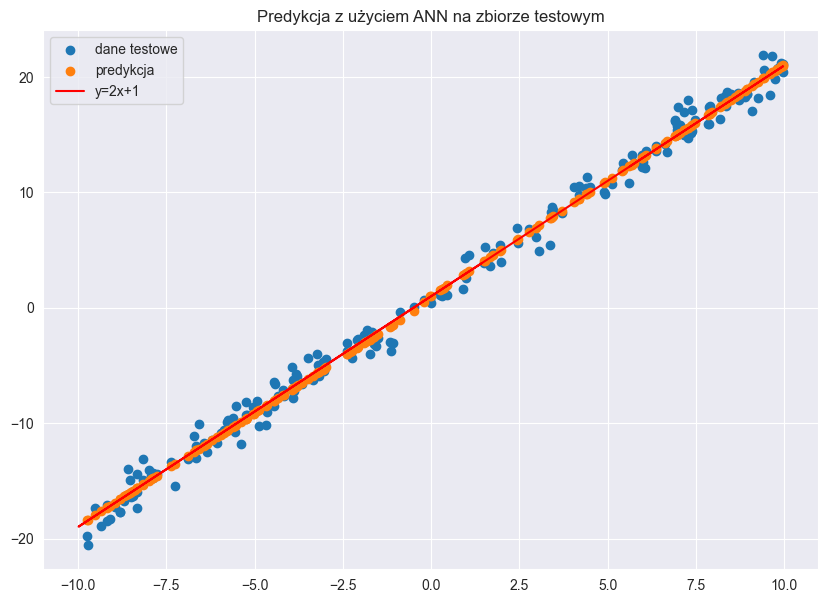

In [19]:
def zad_2():
    ann = MyArtificialNeutralNetwork()
    ann.fit(X_train.T, y_train_scaled.T, units=10, epochs=30000)

    y_pred_scaled = ann.predict(X_test)

    y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1,1)).flatten()

    plt.figure(figsize=(10, 7))
    plt.scatter(X_test, y_test, label="dane testowe")
    plt.scatter(X_test, y_pred, label="predykcja")
    plt.plot(X, line, c='red', label="y=2x+1")
    plt.title("Predykcja z użyciem ANN na zbiorze testowym")
    plt.legend()
    plt.grid(True)
    plt.show()


zad_2()

In [20]:
def build_model(units, activation_fn="relu", optimizer="rmsprop", loss="mse"):
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(units, activation=activation_fn),      # warstwa ukryta
        tf.keras.layers.Dense(1)                                     # warstwa wyjściowa
    ])
    model.compile(optimizer=optimizer, loss=loss)
    return model

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 716us/step - loss: 0.1227
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 696us/step - loss: 0.0349
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 703us/step - loss: 0.0213
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 641us/step - loss: 0.0140
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 616us/step - loss: 0.0086
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0050
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 609us/step - loss: 0.0032
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 639us/step - loss: 0.0020
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 604us/step - loss: 0.0014
Epoch 10/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 585us/step - loss: 9.7458e-04
Epoch 11/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 599us/step - loss: 7.2306e-04
Epoch 12/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 606us/step - loss: 8.9546e-04
Epoch 13/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 621us/step - loss: 7.2258e-04
Epoch 14/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 612us/step - loss: 7.9463e-04
Epoch 15/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 

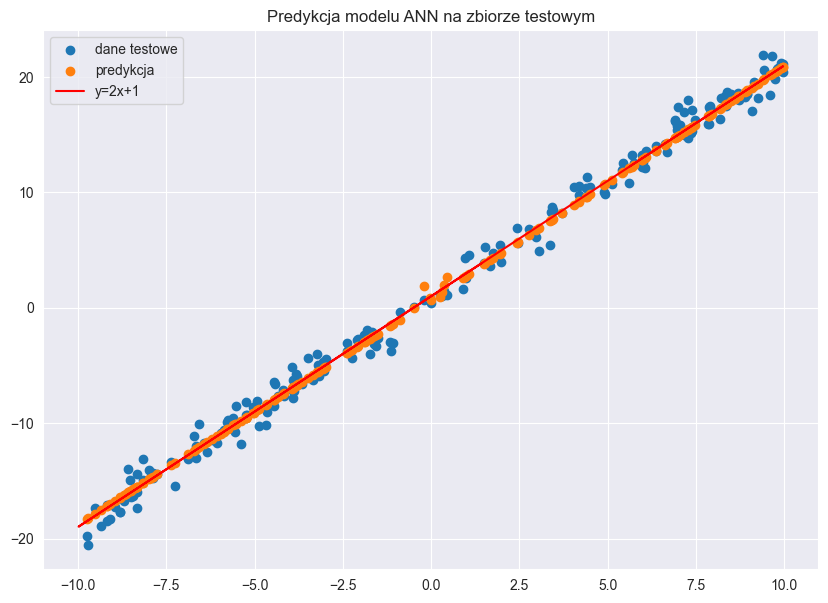

In [21]:
def zad_2_with_tf():
    model = build_model(units=10, activation_fn="relu")
    model.fit(X_train, y_train_scaled, epochs=50)

    y_pred_scaled = model.predict(X_test)
    y_pred = y_scaler.inverse_transform(y_pred_scaled)

    plt.figure(figsize=(10, 7))
    plt.scatter(X_test, y_test, label="dane testowe")
    plt.scatter(X_test, y_pred, label="predykcja")
    plt.plot(X, line, c='red', label="y=2x+1")
    plt.title("Predykcja modelu ANN na zbiorze testowym")
    plt.legend()
    plt.grid(True)
    plt.show()


zad_2_with_tf()

### Zadanie 3

**Funkcje aktywacji:** Zmodyfikuj model z zadania 2, używając różnych funkcji aktywacji dla warstwy ukrytej (np. `ReLU`, `Sigmoid`, `Tanh`). Porównaj, jak wybór funkcji aktywacji wpływa na proces uczenia i ostateczne wyniki.

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 736us/step - loss: 7.9577 
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 700us/step - loss: 4.6712
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 685us/step - loss: 2.5628
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 693us/step - loss: 1.1916
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 612us/step - loss: 0.4655
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 618us/step - loss: 0.2000
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 645us/step - loss: 0.1346
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 750us/step - loss: 0.1088
Epoch 9/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 768us/step - loss: 0.0889
Epoch 10/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 737us/step - loss: 0.0716
Epoch 11/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 714us/step - loss: 0.0560
Epoch 12/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 721us/step - loss: 0.0428
Epoch 13/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 737us/step - loss: 0.0313
Epoch 14/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 721us/step - loss: 0.0219
Epoch 15/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 696us/step - l

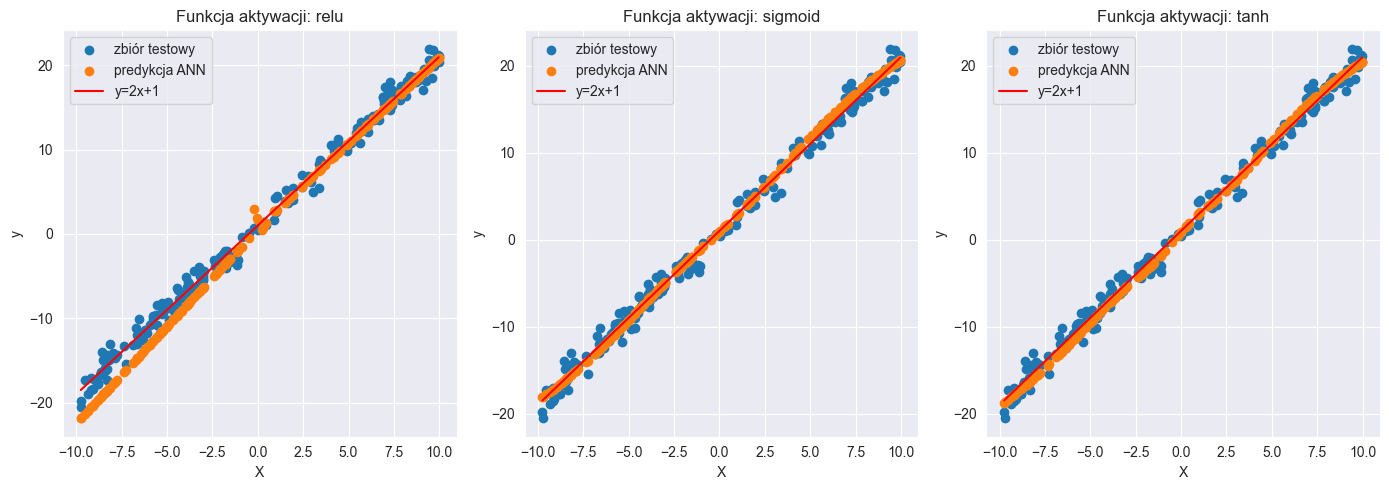

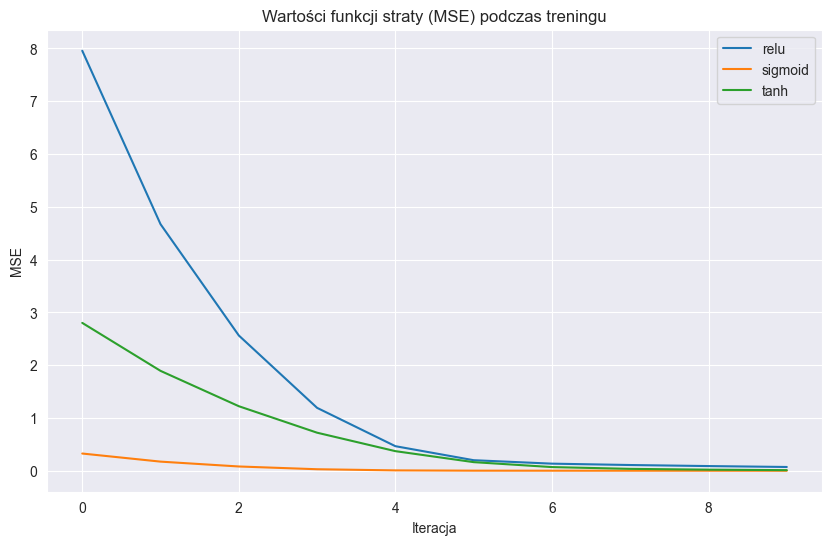

In [18]:
def zad_3():
    activations = ["relu", "sigmoid", "tanh"]

    models = {}

    plt.figure(figsize=(14, 5))

    for i, act in enumerate(activations, 1):
        ann = build_model(units=10, activation_fn=act)
        history = ann.fit(X_train, y_train_scaled, epochs=30)

        y_pred_scaled = ann.predict(X_test)
        y_pred = y_scaler.inverse_transform(y_pred_scaled)
        models[act] = history.history["loss"]

        plt.subplot(1, 3, i)
        plt.scatter(X_test, y_test, label="zbiór testowy")
        plt.scatter(X_test, y_pred, label="predykcja ANN")
        x = np.sort(X_test, axis=0)
        plt.plot(x, 2 * x + 1, c='red', label="y=2x+1")
        plt.title(f"Funkcja aktywacji: {act}")
        plt.grid(True)
        plt.xlabel("X")
        plt.ylabel("y")
        plt.legend()

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 6))

    for act in activations:
        plt.plot(models[act][:10], label=act)

    plt.title("Wartości funkcji straty (MSE) podczas treningu")
    plt.xlabel("Iteracja")
    plt.ylabel("MSE")
    plt.grid(True)
    plt.legend()
    plt.show()


zad_3()

Na podstawie obserwacji można zauważyć, że każda z analizowanych funkcji aktywacji umożliwiła skuteczne uczenie modelu, jednak proces ten przebiegał w różny sposób. W przypadku funkcji `ReLU` widoczny był szybki spadek wartości funkcji straty już na początku treningu, a następnie stopniowe i stabilne jej zmniejszanie w kolejnych iteracjach. Świadczy to o efektywnym przekazywaniu informacji o błędzie i sprawnym dostosowywaniu wag modelu.

Dla funkcji `Tanh` proces uczenia przebiegał w sposób bardziej stopniowy. Wartość błędu `MSE` zmniejszała się regularnie, jednak tempo poprawy było wolniejsze niż w przypadku `ReLU`. Mimo to model z funkcją aktywacji `Tanh` osiągnął niską końcową wartość błędu, co wskazuje, że funkcja ta również dobrze radzi sobie w warstwie ukrytej.

Z kolei zastosowanie funkcji aktywacji `Sigmoid` pozwoliło na uzyskanie niskiej wartości błędu już na wczesnym etapie uczenia. W kolejnych iteracjach zmiany wartości `MSE` były jednak niewielkie, co sugeruje, że model stosunkowo szybko osiągał stan bliski optimum, po czym dalsze uczenie nie prowadziło do znaczącej poprawy wyników. Takie zachowanie jest charakterystyczne dla funkcji `Sigmoid`, której właściwości powodują mniejszą dynamikę zmian w późniejszych etapach treningu.

### Zadanie 4

**Funkcje straty i optymalizatory:** Wykorzystaj model z zadania 2 i przetestuj różne funkcje straty (`MSE` dla regresji, `Binary Cross-Entropy` dla klasyfikacji) oraz optymalizatory (`SGD`, `Adam`). Zwizualizuj krzywą uczenia (spadek błędu w czasie).

In [22]:
X = np.random.uniform(-10, 10, size=(1000, 1))
y = np.sin(X) ** 2 - 1 + np.random.normal(0, 0.1, size=(1000, 1))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = MinMaxScaler()
y_train_scaled = scaler.fit_transform(y_train)
y_test_scaled = scaler.transform(y_test)

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3880 - val_loss: 0.1427
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1292 - val_loss: 0.1190
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1141 - val_loss: 0.1117
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1034 - val_loss: 0.0966
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0947 - val_loss: 0.0913
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0891 - val_loss: 0.0860
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0845 - val_loss: 0.0817
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0809 - val_loss: 0.0822
Epoch 9/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0789 - val_loss: 0.0791
Epoch 10/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0764 - val_loss: 0.0779
Epoch 11/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0744 - val_loss: 0.0756
Epoch 12/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0734 - val_lo

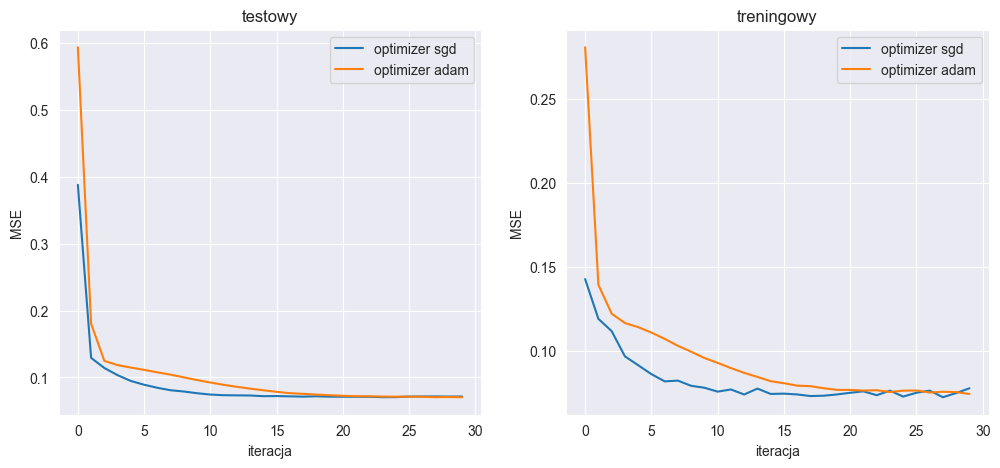

In [23]:
def zad_4_MSE():
    optimizers = ["sgd", "adam"]

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    for optimizer in optimizers:
        model_1 = build_model(units=10, activation_fn='relu', optimizer=optimizer, loss="mse")
        history = model_1.fit(X_train, y_train_scaled, epochs=30, validation_data=(X_test, y_test_scaled))
        ax[0].plot(history.history['loss'], label=f"optimizer {optimizer}")
        ax[1].plot(history.history['val_loss'], label=f"optimizer {optimizer}")
        ax[0].set_title('testowy')
        ax[1].set_title('treningowy')

    ax[0].legend()
    ax[0].grid(True)
    ax[0].set_xlabel('iteracja')
    ax[0].set_ylabel('MSE')
    ax[1].legend()
    ax[1].grid(True)
    ax[1].set_xlabel('iteracja')
    ax[1].set_ylabel('MSE')
    plt.show()


zad_4_MSE()

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7722 - val_loss: 0.7665
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7539 - val_loss: 0.7486
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7391 - val_loss: 0.7339
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7267 - val_loss: 0.7213
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7159 - val_loss: 0.7105
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7064 - val_loss: 0.7007
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6978 - val_loss: 0.6918
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6897 - val_loss: 0.6835
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6820 - val_loss: 0.6756
Epoch 10/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6745 - val_loss: 0.6679
Epoch 11/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6670 - val_loss: 0.6600
Epoch 12/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6593 - val_lo

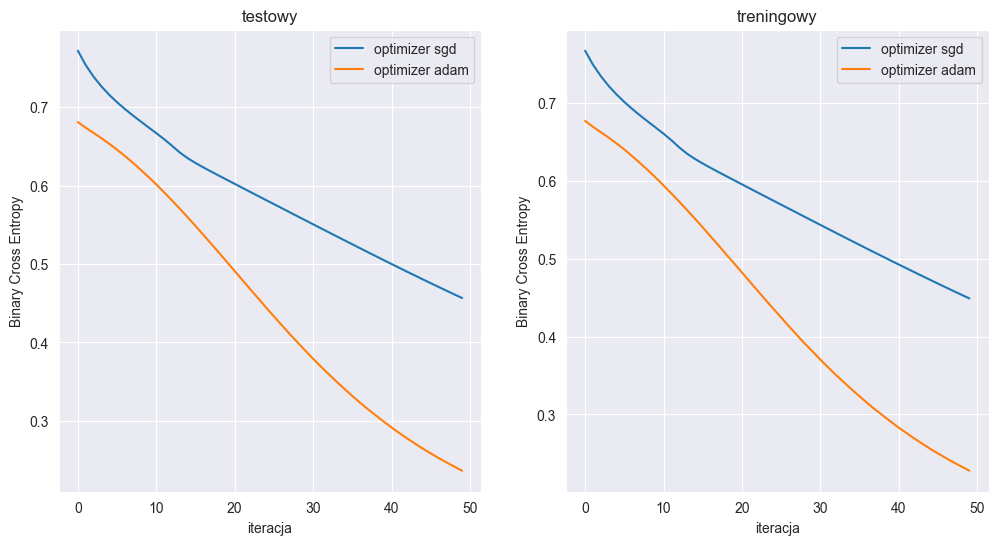

In [24]:
def zad_4_binary_crossentropy():
    X = np.linspace(0, 10, 1000).reshape(-1, 1) + np.random.normal(scale=0.1, size=(1000, 1))
    y = (X > 5).astype(int)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    optimizers = ["sgd", "adam"]

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    for optimizer in optimizers:
        model_1 = tf.keras.Sequential([
            tf.keras.layers.Dense(10, activation="relu"),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

        model_1.compile(optimizer=optimizer, loss="binary_crossentropy")
        history = model_1.fit(X_train_scaled, y_train, epochs=50, validation_data=(X_test_scaled, y_test))
        ax[0].plot(history.history['loss'], label=f"optimizer {optimizer}")
        ax[1].plot(history.history['val_loss'], label=f"optimizer {optimizer}")
        ax[0].set_title('testowy')
        ax[1].set_title('treningowy')

    ax[0].legend()
    ax[0].grid(True)
    ax[0].set_xlabel('iteracja')
    ax[0].set_ylabel('Binary Cross Entropy')
    ax[1].legend()
    ax[1].grid(True)
    ax[1].set_xlabel('iteracja')
    ax[1].set_ylabel('Binary Cross Entropy')
    plt.show()


zad_4_binary_crossentropy()

W obu przypadkach (klasyfikacji i regresji) możemy zaobserwować spadek wartości funkcji straty w czasie, co wskazuje na poprawne działanie modeli oraz skuteczność zastosowanych metod optymalizacji. Uzyskane wyniki pokazują, że wybór optymalizatora może zależeć od złożoności modelu oraz charakteru rozwiązywanego problemu. Dla prostszych modeli regresyjnych klasyczny optymalizator SGD może okazać się wystarczający, natomiast w przypadku złożonych danych i modeli bardziej zaawansowane metody optymalizacji, takie jak Adam, mogą zapewniać szybszą i efektywniejszą konwergencję.

### Zadanie 5

**Klasyfikacja binarnego problemu:** Wczytaj zbiór danych `Breast Cancer` i zbuduj prostą sieć neuronową do klasyfikacji binarnej. Użyj odpowiedniej funkcji straty i funkcji aktywacji dla warstwy wyjściowej (sigmoid). Oceń model, obliczając jego dokładność na zbiorze testowym.

In [31]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, precision_score, recall_score


def zad_5():
    data = load_breast_cancer(as_frame=True).frame

    X = data.drop('target', axis=1)
    y = data['target']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    breast_cancer_scaler = MinMaxScaler()
    breast_cancer_scaler.fit(X_train)
    X_train_scaled = breast_cancer_scaler.transform(X_train)
    X_test_scaled = breast_cancer_scaler.transform(X_test)

    model_1 = tf.keras.Sequential([
        tf.keras.layers.Dense(units=10, activation="sigmoid"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])

    model_1.compile(optimizer='adam', loss='binary_crossentropy')

    history = model_1.fit(X_train_scaled, y_train, epochs=50)

    y_pred_test = model_1.predict(X_test_scaled)
    y_pred_test = (y_pred_test > 0.5).astype(int)
    y_pred_train = model_1.predict(X_train_scaled)
    y_pred_train = (y_pred_train > 0.5).astype(int)

    accuracy_test = accuracy_score(y_test, y_pred_test)
    precision_test = precision_score(y_test, y_pred_test)
    recall_test = recall_score(y_test, y_pred_test)
    accuracy_train = accuracy_score(y_train, y_pred_train)
    precision_train = precision_score(y_train, y_pred_train)
    recall_train = recall_score(y_train, y_pred_train)

    display(pd.DataFrame({"Accuracy": [accuracy_train, accuracy_test],
                  "Precision": [precision_train, precision_test],
                  "Recall": [recall_train, recall_test]}, index=['train', 'test']))


zad_5()

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6461  
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6321 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6215
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6100
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6003 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5907 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5820
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5732
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5648
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5568
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 989us/step - loss: 0.5485
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 990us/step - loss: 0.5407
Epoch 13/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5329
Epoch 14/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5256
Epoch 15/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5182
Epoch 16/5

,Accuracy,Precision,Recall
train,0.923077,0.900958,0.986014
test,0.947368,0.922078,1.000000


Klasyfikacja binarna została dokonana na zbiorze danych `Breast Cancer`, pochodzącym z biblioteki `scikit-learn`. Dane te zostały podzielone na zbiór treningowy i testowy. Model został skonstruowany w odpowiedni sposób tak, aby nadawał się do przeprowadzenia klasyfikacji binarnej. Zarówno dla zbioru treningowego, jak i testowego po wytrenowaniu modelu zmierzone zostały statystyki takie jak dokładność, precyzja i czułość. Dla obu zbiorów model osiągnął wysokie wartości tychże statystyk, przy czym wartości te były większe dla zbioru testowego. Sugeruje to, że nie doszło do zjawiska przeuczenia, a model dobrze dopasował się do danych i zwraca możliwie poprawne predykcje.

### Zadanie 6

**Overfitting i techniki regularizacji:** Przeprowadź eksperyment, w którym wytrenujesz „duży” model na małym zbiorze danych, aby spowodować przeuczenie. Zastosuj techniki regularyzacji, takie jak `dropout` i `L2`, aby złagodzić ten problem. Porównaj krzywe treningowe (błąd na zbiorze treningowym i walidacyjnym).

In [26]:
from sklearn.preprocessing import StandardScaler
import tensorflow as tf


(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
X_train = X_train.reshape(-1, 28 * 28)
X_test = X_test.reshape(-1, 28 * 28)

print("Rozmiar danych: ", X_train.shape)

X_train = X_train[:500]     # Ograniczenie zbioru danych do 500 rekordów
y_train = y_train[:500]
X_test = X_test[:500]
y_test = y_test[:500]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Rozmiar danych:  (60000, 784)


In [27]:
model_without_regularization = tf.keras.Sequential([
        tf.keras.layers.Dense(500, activation='relu'),
        tf.keras.layers.Dense(500, activation='relu'),
        tf.keras.layers.Dense(500, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

model_without_regularization.compile(
    loss="sparse_categorical_crossentropy"
)

history_without_regularization = model_without_regularization.fit(
    X_train, y_train,
    epochs=50,
    validation_data = (X_test, y_test),
    batch_size=32,
    verbose=0
)

In [32]:
model_regularized = tf.keras.Sequential([
    tf.keras.layers.Dense(500, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-3),),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(500, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-3),),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(500, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-3),),
    tf.keras.layers.Dropout(0.3),
tf.keras.layers.Dense(10, activation='softmax')
])

model_regularized.compile(
    loss='sparse_categorical_crossentropy'
)

hist_regularized = model_regularized.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 3.0806 - val_loss: 3.1359
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.9467 - val_loss: 2.9484
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.7587 - val_loss: 2.4453
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.5528 - val_loss: 2.5359
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.4507 - val_loss: 2.9593
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.3723 - val_loss: 2.2646
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.2642 - val_loss: 3.1568
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.1392 - val_loss: 2.1425
Epoch 9/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.0678 - val_loss: 2.1627
Epoch 10/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.0128 - val_loss: 1.9459
Epoch 11/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.9113 - val_loss: 2.1041
Epoch 12/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.8576 - val

In [29]:
import matplotlib.pyplot as plt


def plot_history(history, title):
    plt.plot(history.history["loss"], label="train loss")
    plt.plot(history.history["val_loss"], label="test loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

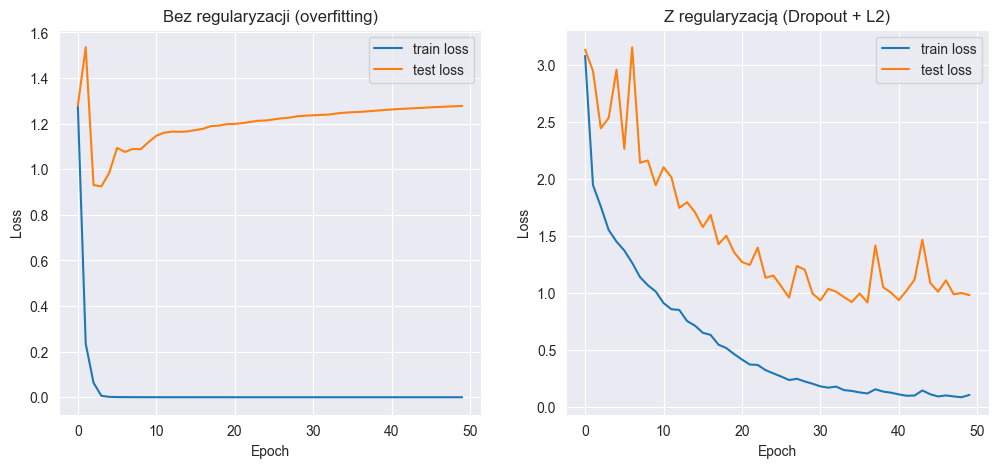

In [33]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plot_history(history_without_regularization, "Bez regularyzacji (overfitting)")

plt.subplot(1, 2, 2)
plot_history(hist_regularized, "Z regularyzacją (Dropout + L2)")

plt.show()

Model w tym zadaniu został wytrenowany na danych pochodzących z `MNIST`'u zawierających zdjęcia/obrazy cyfr. Zdecydowałam się na ten zbiór danych ze względu na jego złożoność i rozmiar — dla mniejszych i separowalnych zbiorów danych nawet "duże" i złożone modele sieci neuronowych nie były podatne na zjawisko przeuczenia. Dane treningowe i testowe zostały ograniczone do 500 rekordów. Następnie wytrenowałam dwa modele — pierwszy z trzema warstwami ukrytymi zawierającymi 500 neuronów każda, drugi analogiczny, ale z zastosowaniem technik regularyzacji takimi jak `Dropout` i `L2`. Następnie zwizualizowałam krzywą uczenia.

Jak możemy zauważyć, w obu przypadkach krzywa uczenia spada wraz z ilością iteracji dla zbioru treningowego, natomiast w przypadku modelu bez regularyzacji strata nie spada, a wręcz rośnie z każdym kolejnym przejściem przez sieć. Oznacza to, że model zbyt mocno dopasował się do danych treningowych i nie działa odpowiednio dla danych testowych. Techniki regularyzacji sprawiły, że dla modelu 2 funkcja straty maleje z każdą kolejną iteracją i model nie doświadcza zjawiska przeuczenia.